### Project objective
Develop an intelligent traffic signal system that learns to control traffic lights based on vehicle congestion at a four-way intersection.

The RL agent will learn:
- Which road has more traffic.
- Which signal should receive green.
- How long a signal should remain green.
- How to reduce vehicle waiting time and congestion.

### Expected outcome: 
A trained RL agent that learns a traffic signal control strategy through repeated simulation.

#### Phase 1 – Jupyter Notebook setup
Let's start coding.

# Step 2. Project introduction
# Intelligent Traffic Signal Control Using Reinforcement Learning

## Project Objective
To develop an intelligent traffic signal control system using Q-Learning that learns to optimize traffic signal decisions based on vehicle congestion.

## Problem Statement
Fixed-time traffic signals may not respond effectively to changing traffic conditions. This project explores an adaptive signal control strategy using Reinforcement Learning.

## Algorithm
Q-Learning (Model-Free Reinforcement Learning)

## Technologies
- Python
- NumPy
- Pandas
- Matplotlib
- Jupyter Notebook
- React (Frontend – Future Phase)

### Step 3. Import libraries
Create a code cell and execute:

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random

In [67]:
roads = [ 'North', 'South', 'East', 'West' ]
print(roads)

['North', 'South', 'East', 'West']


In [68]:
traffic = { "North": 10, "South": 15, "East": 5, "West": 20}
print(traffic)

{'North': 10, 'South': 15, 'East': 5, 'West': 20}


In [69]:
total_vehicles = sum(traffic.values())
print(total_vehicles)

50


In [70]:
north_south = traffic["North"] + traffic["South"]

east_west = traffic["East"] + traffic["West"]

print("North-South traffic:", north_south)
print("East-West traffic:", east_west)

North-South traffic: 25
East-West traffic: 25


In [71]:
# Visualize traffic congestion
# Before implementing RL, let's visualize our traffic data.


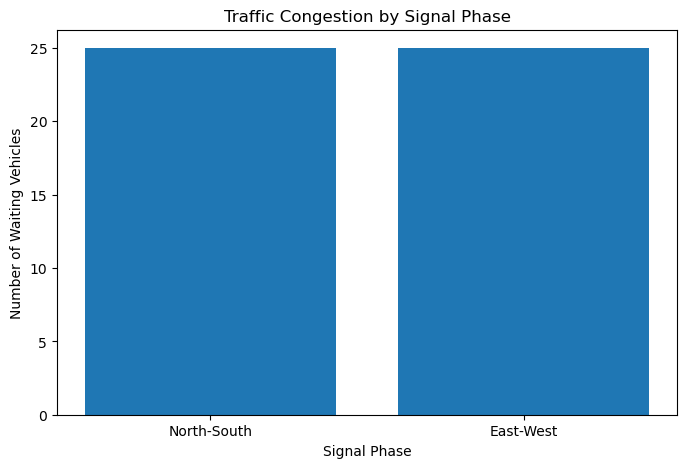

In [72]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["North-South", "East-West"],
    [north_south, east_west]
)

plt.title("Traffic Congestion by Signal Phase")
plt.xlabel("Signal Phase")
plt.ylabel("Number of Waiting Vehicles")

plt.show()

In [73]:
# Generate random vehicle arrivals
# In a real traffic intersection, vehicles continuously arrive from different roads.

# We will simulate this using Python's random library.

new_arrivals = {'North': 3, 'South': 2, 'East': 4, 'West': 1}

for road in roads:
    new_arrivals[road] = random.randint(0, 5)

print("New vehicle arrivals:", new_arrivals)

New vehicle arrivals: {'North': 5, 'South': 4, 'East': 3, 'West': 2}


In [74]:
# Notice that East has the highest new arrivals, while West has no new arrivals in this simulation step.

# Update the traffic queue
# Now we need to combine: i.e

# Existing vehicles + New vehicle arrivals = Updated traffic queue

updated_traffic = {'North': 12, 'South': 18, 'East': 10, 'West': 20}

for road in roads:
    updated_traffic[road] = traffic[road] + new_arrivals[road]

print(updated_traffic)

{'North': 15, 'South': 19, 'East': 8, 'West': 22}


In [75]:
green_phase = "North-South"
if road == "North" or road == "South":
    print("Green signal")

In [76]:
# Now let's extend the logic.
# We want to create a dictionary that stores vehicle departures.

departures = {}

for road in roads:
    if road == "North" or road == "South":
        departures[road] = 5
    else:
        departures[road] = 0

print(departures)

{'North': 5, 'South': 5, 'East': 0, 'West': 0}


In [77]:
# Create a dictionary called remaining_traffic.
# Complete this code:

remaining_traffic = {}

for road in roads:
    remaining_traffic[road] = updated_traffic[road]-departures[road]

print(remaining_traffic)

{'North': 10, 'South': 14, 'East': 8, 'West': 22}


In [78]:
# Let's calculate how many vehicles are still waiting across all four roads.

total_remaining = sum(remaining_traffic.values())

print("Total remaining vehicles:", total_remaining)

Total remaining vehicles: 54


In [79]:
green_phase = "East-West"

In [80]:
for road in roads:
    if road == "East" or road == "West":
        departures[road] = 5
    else:
        departures[road] = 0

In [81]:
# or this code can handel both the conditions 

for road in roads:
    if green_phase == "North-South" and (road == "North" or road == "South"):
        departures[road] = 5
    elif green_phase == "East-West" and (road == "East" or road == "West"):
        departures[road] = 5
    else:
        departures[road] = 0

print(green_phase)

East-West


In [82]:
# Calculating the departures

departures = {}

for road in roads:
    if green_phase == "North-South" and (road == "North" or road == "South"):
        departures[road] = 5

    elif green_phase == "East-West" and (road == "East" or road == "West"):
        departures[road] = 5

    else:
        departures[road] = 0

print(departures)

{'North': 0, 'South': 0, 'East': 5, 'West': 5}


In [83]:
# Update the remaining traffic
# Remaining = Updated\ Traffic - Departures

remaining_traffic = {}

for road in roads:
    remaining_traffic[road] = updated_traffic[road] - departures[road]

print(remaining_traffic)

{'North': 15, 'South': 19, 'East': 3, 'West': 17}


In [84]:
print(updated_traffic)
print(departures)
print(remaining_traffic)

{'North': 15, 'South': 19, 'East': 8, 'West': 22}
{'North': 0, 'South': 0, 'East': 5, 'West': 5}
{'North': 15, 'South': 19, 'East': 3, 'West': 17}


In [85]:
# Now let's implement this in Python.
# Step 1: Calculate the total traffic before and after

total_before = sum(updated_traffic.values())
total_after = sum(remaining_traffic.values())

print("Traffic before:", total_before)
print("Traffic after:", total_after)

Traffic before: 64
Traffic after: 54


In [86]:
# Step 2: Calculate the reward

if total_after < total_before:
    reward = 10
elif total_after == total_before:
    reward = 0
else:
    reward = -10

print("Reward:", reward)

Reward: 10


In [87]:
actions = ["North-South", "East-West"]
states = [0, 1, 2]
print(actions)
print(states)

['North-South', 'East-West']
[0, 1, 2]


In [88]:
# Create the Q-table
# create a NumPy array containing three rows and two columns.

q_table = np.zeros((len(states), len(actions)))

print(q_table)


[[0. 0.]
 [0. 0.]
 [0. 0.]]


In [89]:
# Understand the Q-table structure

q_table = np.zeros((len(states), len(actions)))

In [90]:
# Check the Q-table dimensions

print("Q-table shape:", q_table.shape)

Q-table shape: (3, 2)


In [91]:
# Access individual Q-values

print(q_table[0][0])
print(q_table[0][1])
print(q_table[1][0])
print(q_table[1][1])


0.0
0.0
0.0
0.0


In [92]:
# Example q_table

q_table[2][1] = 10

print(q_table)
# Important: This is a manual change, not RL training. Later, the Q-learning algorithm will update these values automatically.

[[ 0.  0.]
 [ 0.  0.]
 [ 0. 10.]]


In [93]:
# How does the agent select the best action?

state = 2

best_action = np.argmax(q_table[state])

print("Best action index:", best_action)
print("Best action:", actions[best_action])

Best action index: 1
Best action: East-West


In [94]:
# First, let's create the environment data

states = ["Low", "Medium", "High"]

actions = ["North-South", "East-West"]

q_table = np.zeros((3, 2))

print("Q-table:")
print(q_table)

Q-table:
[[0. 0.]
 [0. 0.]
 [0. 0.]]


In [95]:
# once again initializing

import numpy as np

states = ["Low", "Medium", "High"]
actions = ["North-South", "East-West"]

q_table = np.zeros((3, 2))

alpha = 0.1
gamma = 0.9

In [96]:
# Building update_q_table function

def update_q_table(state, action, reward, next_state):

    state_index = states.index(state)
    action_index = actions.index(action)

    # Retrieve the existing Q-value
    old_q_value = q_table[state_index, action_index]

    # Identify the next state
    next_state_index = states.index(next_state)

    # Find the maximum Q-value of the next state
    max_next_q = np.max(q_table[next_state_index])

    # Calculate the new Q-value
    new_q_value = old_q_value + alpha * (
        reward + gamma * max_next_q - old_q_value
    )

    # Store the updated Q-value
    q_table[state_index, action_index] = new_q_value

    # Return the updated Q-value
    return new_q_value

In [97]:
# let's test our function

updated_value = update_q_table(
    "High",
    "East-West",
    10,
    "Medium"
)

print("Updated Q-value:", updated_value)
print("\nUpdated Q-table:")
print(q_table)

Updated Q-value: 1.0

Updated Q-table:
[[0. 0.]
 [0. 0.]
 [0. 1.]]


In [98]:
# test whether learning happens again

updated_value = update_q_table(
    "High",
    "East-West",
    10,
    "Medium"
)

print("Updated Q-value:", updated_value)
print(q_table)

Updated Q-value: 1.9
[[0.  0. ]
 [0.  0. ]
 [0.  1.9]]


In [99]:
# Now execuiting the same function, calling again, the q-table should be updated

updated_value = update_q_table(
    "High",
    "East-West",
    10,
    "Medium"
)

print("Updated Q-value:", updated_value)
print(q_table)

Updated Q-value: 2.71
[[0.   0.  ]
 [0.   0.  ]
 [0.   2.71]]


In [100]:
# Doing Agian
updated_value = update_q_table(
    "High",
    "East-West",
    10,
    "Medium"
)

print("Updated Q-value:", updated_value)
print(q_table)

Updated Q-value: 3.439
[[0.    0.   ]
 [0.    0.   ]
 [0.    3.439]]


#### This confirms that your Q-table is being updated repeatedly rather than manually assigned.

### Next, we'll build the complete RL learning loop 
so the agent selects actions, interacts with the environment, receives rewards and updates the Q-table automatically.

#### That is where our practical RL program starts behaving like an actual learning agent!

In [101]:
# Step 2 : Prepare a fresh Q-table
# Since we experimented with repeated updates yesterday, our current Q-table contains 3.439.
# For a clean learning experiment, reset it:

q_table = np.zeros((3, 2))
# This starts our new training with no prior knowledge.

In [102]:
episodes =10

In [103]:
# Step 4: Prepare the starting state
# Let's assume every episode starts with High traffic.

current_state = "High"
# We will later make the starting state vary.

In [104]:
# Showing all this conditions together
q_table = np.zeros((3, 2))

episodes = 10

current_state = "High"

In [105]:
# Our fresh Q-table is ready.
# Now let's make the agent select an action automatically.

# Step 5: Agent action selection
# Currently, our agent has two possible actions:

actions = ["North-South", "East-West"]

# We want the agent to look at the Q-table and select the action with the highest Q-value., We can use this now

action_index = np.argmax(q_table[states.index(current_state)])
action = actions[action_index]
print("Current State:", current_state)
print("Selected Action:", action)

# Both actions have equal Q-values. np.argmax() returns the first maximum, so it selects North-South.
# Important: This is only temporary action selection.
# Later, we'll introduce exploration so the agent can try both actions instead of always selecting the first one when values are equal.

Current State: High
Selected Action: North-South


#### Step 6: Connect the agent to the environment
Now the agent has selected an action. We need to send that action to the environment.

Remember our previously created function:

In [106]:
environment = {
    "High": {
        "North-South": (5, "Medium"),
        "East-West": (10, "Medium")
    },
    "Medium": {
        "North-South": (8, "Low"),
        "East-West": (3, "High")
    },
    "Low": {
        "North-South": (10, "Low"),
        "East-West": (5, "Medium")
    }
}

In [107]:
def environment_step(state, action):

    reward, next_state = environment[state][action]

    return reward, next_state

In [108]:
# calling it

reward, next_state = environment_step(current_state, action)

print("Selected Action:", action)
print("Reward:", reward)
print("Next State:", next_state)

Selected Action: North-South
Reward: 5
Next State: Medium


### complete Step 7: Update the Q-table

In [109]:
updated_value = update_q_table(
    current_state,
    action,
    reward,
    next_state
)

print("Updated Q-value:", updated_value)
print("\nUpdated Q-table:")
print(q_table)

# Q_{new}=0+0.1(5+0.9(0)-0)=0.5
# The agent has learned its first value from the environment.

Updated Q-value: 0.5

Updated Q-table:
[[0.  0. ]
 [0.  0. ]
 [0.5 0. ]]


In [110]:
# In the above cell, in first run you got 0.5, and in second run you got 0.95, check and trace. similarlly it keep updated with new values

In [111]:
# Step 8: Update the current state

current_state = next_state
print("New Current State:", current_state)

New Current State: Medium


In [112]:
for step in range(5):
    print("Step:", step)

Step: 0
Step: 1
Step: 2
Step: 3
Step: 4


In [113]:
# Now the agent moves through the environment
# This is the Agent's complete learning loop

for step in range(5):

    print("Step:", step)

    state_index = states.index(current_state)

    action_index = np.argmax(q_table[state_index])

    action = actions[action_index]

    reward, next_state = environment_step(current_state, action)

    update_q_table(current_state, action, reward, next_state)

    current_state = next_state

    print("Action:", action)
    print("Reward:", reward)
    print("Next State:", next_state)
    print("-------------------")

Step: 0
Action: North-South
Reward: 8
Next State: Low
-------------------
Step: 1
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 2
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 3
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 4
Action: North-South
Reward: 10
Next State: Low
-------------------


In [114]:
# Your first automated Q-Learning loop has executed successfully!
# Now your agent is interacting with the environment without you manually providing each action.

# Check your updated Q-table
print(q_table)

[[3.940399 0.      ]
 [0.8      0.      ]
 [0.5      0.      ]]


* "np.argmax()" always selects the action with the highest Q-value.
* When both actions have equal Q-values, it selects the first action.
* Therefore, our agent doesn't explore other possibilities.
* This is an important limitation of our current implementation.

What does this tell us?
- Low: North-South has learned a Q-value of 3.940399.
- Medium: North-South has learned 0.8.
- High: North-South has learned 0.95.
- East-West: All values remain zero because the agent hasn't tried that action.
Important: Zero doesn't mean East-West is a bad action. It means our agent hasn't learned its value yet.

#### Now let's introduce Epsilon-Greedy
This strategy balances two behaviours:
##### Exploitation 80%
Select the action with the highest known Q-value.
##### Exploration 20%
Select a random action to discover potentially better rewards.

In [115]:
#  Let's understand the Python logic first : We use Python's random module.
# running this code more then 5-8 times we can see the changes in the selection

import random

epsilon = 0.2

if random.random() < epsilon:
    print("Explore")
else:
    print("Exploit")

Exploit


Because we set epsilon =0.2, 
- 20% probability: Explore (try a random action).
- 80% probability: Exploit (choose the action with the highest Q-value).
One important point: It doesn't mean the agent must explore exactly once in every five attempts. Each decision is random and independent.

Next step: Connect this to our traffic example
Let's build the actual action-selection logic.

You already know:
- state_index identifies the current state's row in the Q-table.
- np.argmax() selects the action with the highest Q-value.
Now, try completing this code:

In [116]:
if random.random() < epsilon:
    action_index = random.randrange(len(actions))
else:
    action_index = np.argmax(q_table[state_index])

action = actions[action_index]
print("Selected Action:", action)

Selected Action: East-West


Running the above code muiltiple times, 
You got:
- North-South: selected many times.
- East-West: selected once in approximately 6–7 attempts.
because our agent has two ways of selecting actions:
1. Exploration (20%) – randomly selects either North-South or East-West.
2. Exploitation (80%) – selects the action with the highest Q-value.

One important detail: East-West appearing once doesn't necessarily mean exploration happened once. 
It could also have been selected during exploitation if its Q-value was higher.

#### Next step: Integrate into our learning loop
Now we'll replace the old greedy action-selection code in our existing 5-step loop with the epsilon-greedy logic.

In [117]:
# If we are replacing the above 'Learning 5-step learning loop, see the changes now

for step in range(5):

    print("Step:", step)

    state_index = states.index(current_state)

    # Exploration and Exploitation
    if random.random() < epsilon:
        action_index = random.randrange(len(actions))
        print("Decision: Explore")
    else:
        action_index = np.argmax(q_table[state_index])
        print("Decision: Exploit")

    action = actions[action_index]

    reward, next_state = environment_step(current_state, action)

    update_q_table(current_state, action, reward, next_state)

    current_state = next_state

    print("Action:", action)
    print("Reward:", reward)
    print("Next State:", next_state)
    print("-------------------")

Step: 0
Decision: Explore
Action: East-West
Reward: 5
Next State: Medium
-------------------
Step: 1
Decision: Exploit
Action: North-South
Reward: 8
Next State: Low
-------------------
Step: 2
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 3
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 4
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------


In [118]:
# Check for Q-table to confirm why it is selecting the same 
print(q_table)

[[6.79346521 0.572     ]
 [1.87463591 0.        ]
 [0.5        0.        ]]


#### Now we're going to see whether our agent actually learns to explore different actions and improves its Q-table.


Step 1: Increase learning steps

Now we'll run it for 100 steps.
One small preparation: set the starting state back to High, but keep the existing Q-table. 
We want to continue learning from what the agent has already learned.

In [119]:
current_state = "High"

Step 2: Update the learning loop

Use the same code as before, with one change: range(5) becomes range(100).

In [121]:
for step in range(100):

    print("Step:", step)

    state_index = states.index(current_state)

    # Exploration and Exploitation
    if random.random() < epsilon:
        action_index = random.randrange(len(actions))
        print("Decision: Explore")
    else:
        action_index = np.argmax(q_table[state_index])
        print("Decision: Exploit")

    action = actions[action_index]

    reward, next_state = environment_step(current_state, action)

    update_q_table(current_state, action, reward, next_state)

    current_state = next_state

    print("Action:", action)
    print("Reward:", reward)
    print("Next State:", next_state)
    print("-------------------")

Step: 0
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 1
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 2
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 3
Decision: Explore
Action: East-West
Reward: 5
Next State: Medium
-------------------
Step: 4
Decision: Exploit
Action: North-South
Reward: 8
Next State: Low
-------------------
Step: 5
Decision: Explore
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 6
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 7
Decision: Explore
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 8
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 9
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 10
Decision: Exploit
Action: North-South
Reward: 10
Next State: L

Step 3: Check the Q-table

After the loop finishes, run:

In [122]:
print(q_table)

[[78.94015538 35.15671361]
 [55.68443689  0.82133072]
 [ 4.37969902  0.        ]]


Let's decode it.
1. Map the Q-table
Remember our mapping:
- Rows: Low, Medium, High
- Columns: North-South, East-West
State	North-South	East-West
Low	     57.44  	12.22
Medium   26.43    	 0
High	 1.427  	 0

2. What has the agent learned?
Low state:
- North-South = 57.44
- East-West = 12.22
The agent currently considers North-South the better action.

Medium state:
- North-South = 26.43
- East-West = 0
It has updated North-South but hasn't explored East-West from Medium.

High state:
- North-South = 1.427
- East-West = 0
It has also updated North-South but hasn't explored East-West from High.
3. An important observation
Look at the East-West values.

Only the Low-state East-West value has changed from zero.

That means the agent has explored East-West from Low, but apparently hasn't tried it from Medium or High yet.

Remember, exploration selects a random action, but it doesn't guarantee every state-action combination gets explored.

In [123]:
# 4. Let's check the agent's current policy

for i in range(len(states)):

    best_action_index = np.argmax(q_table[i])

    best_action = actions[best_action_index]

    print(states[i], "->", best_action)

Low -> North-South
Medium -> North-South
High -> North-South


In [124]:
print(state)

2


#### Create multiple episodes

In [127]:
# We now want to introduce an outer loop for episodes.
# Agent selects action
# Environment returns reward and next state
# Q-table gets updated.

for episode in range(10):

    current_state = "High"

    print("Episode:", episode + 1)

    for step in range(10):

        state_index = states.index(current_state)

        if random.random() < epsilon:
            action_index = random.randrange(len(actions))
            decision = "Explore"
        else:
            action_index = np.argmax(q_table[state_index])
            decision = "Exploit"

        action = actions[action_index]

        reward, next_state = environment_step(current_state, action)

        update_q_table(current_state, action, reward, next_state)

        current_state = next_state

        print("Step:", step + 1)
        print("Decision:", decision)
        print("Action:", action)
        print("Reward:", reward)
        print("Next State:", next_state)
        print("-------------------")

    print("Episode completed")
    print("===================")

Episode: 1
Step: 1
Decision: Exploit
Action: North-South
Reward: 5
Next State: Medium
-------------------
Step: 2
Decision: Exploit
Action: North-South
Reward: 8
Next State: Low
-------------------
Step: 3
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 4
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 5
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 6
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 7
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 8
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 9
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Step: 10
Decision: Exploit
Action: North-South
Reward: 10
Next State: Low
-------------------
Episode completed
Episode: 2
Step: 1
Decision: Exploit
Ac

In [128]:
# Let's inspect the Q-table
print(q_table)

[[89.15129235 47.84958883]
 [78.34552466  7.48612814]
 [48.4758752   7.95825977]]


In [129]:
# Then now run our policy extraction code:

for i in range(len(states)):

    best_action_index = np.argmax(q_table[i])

    best_action = actions[best_action_index]

    print(states[i], "->", best_action)

Low -> North-South
Medium -> North-South
High -> North-South


Now one important RL concept,
As the agent learns, we generally want it to explore less and exploit more.   This is called Epsilon Decay.

In [132]:
# Step 1: Let's implement Epsilon Decay in Python
# We'll use our existing traffic junction project.
# Suppose we start with:

epsilon = 1.0           # Current exploration probability
epsilon_decay = 0.995   # How quickly exploration reduces
epsilon_min = 0.01      # Minimum exploration probability

In [131]:
# Now After every episode, we update epsilon:

epsilon = max(epsilon_min, epsilon * epsilon_decay)

In [134]:
# Step 3: Your coding task
# In our existing Q-learning program, we need to add epsilon decay after each episode.
# Find your existing episode loop:

for episode in range(episodes):
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
print(q_table)
print(epsilon)


[[89.15129235 47.84958883]
 [78.34552466  7.48612814]
 [48.4758752   7.95825977]]
0.9046104802746175


In [135]:
# Combine everything

# Training parameters

epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01

episodes = 100

In [136]:
for episode in range(episodes):

    current_state = "High"

    for step in range(10):

        state_index = states.index(current_state)

        # Exploration and Exploitation
        if random.random() < epsilon:
            action_index = random.randrange(len(actions))
        else:
            action_index = np.argmax(q_table[state_index])

        action = actions[action_index]

        # Interact with environment
        reward, next_state = environment_step(current_state, action)

        # Update Q-table
        update_q_table(current_state, action, reward, next_state)

        current_state = next_state

    # Epsilon decay after each episode
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if (episode + 1) % 10 == 0:
        print("Episode:", episode + 1, "| Epsilon:", epsilon)

Episode: 10 | Epsilon: 0.9511101304657719
Episode: 20 | Epsilon: 0.9046104802746175
Episode: 30 | Epsilon: 0.8603841919146962
Episode: 40 | Epsilon: 0.8183201210226743
Episode: 50 | Epsilon: 0.778312557068642
Episode: 60 | Epsilon: 0.7402609576967045
Episode: 70 | Epsilon: 0.7040696960536299
Episode: 80 | Epsilon: 0.6696478204705644
Episode: 90 | Epsilon: 0.6369088258938781
Episode: 100 | Epsilon: 0.6057704364907278


In [156]:
print("Final Q-table:")
print(q_table)

print("\nFinal Epsilon:")
print(epsilon)

Final Q-table:
[[99.99975135 92.21693045]
 [97.99907365 90.16815213]
 [93.1969618  97.19398601]]

Final Epsilon:
0.6057704364907278


In [157]:
# And extract the learned policy:

for i in range(len(states)):

    best_action_index = np.argmax(q_table[i])
    best_action = actions[best_action_index]

    print(states[i], "->", best_action)

Low -> North-South
Medium -> North-South
High -> East-West


In [151]:
total_reward = 0
total_reward += reward
# after completeion of each loop
print("Episode:", episode + 1,
      "Total Reward:", total_reward)

Episode: 100 Total Reward: 10


In [158]:
for episode in range(episodes):

    total_reward = 0  # Reset for each episode

    for step in range(10):

        # Your action selection code
        reward, next_state = environment_step(current_state, action)

        total_reward += reward  # Accumulate each step's reward

        # Your Q-table update code

    # After all 10 steps
    print("Episode:", episode + 1,
          "Total Reward:", total_reward)

Episode: 1 Total Reward: 100
Episode: 2 Total Reward: 100
Episode: 3 Total Reward: 100
Episode: 4 Total Reward: 100
Episode: 5 Total Reward: 100
Episode: 6 Total Reward: 100
Episode: 7 Total Reward: 100
Episode: 8 Total Reward: 100
Episode: 9 Total Reward: 100
Episode: 10 Total Reward: 100
Episode: 11 Total Reward: 100
Episode: 12 Total Reward: 100
Episode: 13 Total Reward: 100
Episode: 14 Total Reward: 100
Episode: 15 Total Reward: 100
Episode: 16 Total Reward: 100
Episode: 17 Total Reward: 100
Episode: 18 Total Reward: 100
Episode: 19 Total Reward: 100
Episode: 20 Total Reward: 100
Episode: 21 Total Reward: 100
Episode: 22 Total Reward: 100
Episode: 23 Total Reward: 100
Episode: 24 Total Reward: 100
Episode: 25 Total Reward: 100
Episode: 26 Total Reward: 100
Episode: 27 Total Reward: 100
Episode: 28 Total Reward: 100
Episode: 29 Total Reward: 100
Episode: 30 Total Reward: 100
Episode: 31 Total Reward: 100
Episode: 32 Total Reward: 100
Episode: 33 Total Reward: 100
Episode: 34 Total R

In [159]:
episode_rewards = []  # Before training starts

for episode in range(episodes):

    total_reward = 0  # Reset at the start of each episode

    for step in range(10):

        # Your existing action selection code
        # Your environment_step code

        total_reward += reward

        # Your existing Q-table update code

    episode_rewards.append(total_reward)  # After each episode

In [160]:
print("Number of episodes:", len(episode_rewards))
print("First 10 episode rewards:", episode_rewards[:10])
print("Average reward:", np.mean(episode_rewards))
print("Maximum reward:", max(episode_rewards))
print("Minimum reward:", min(episode_rewards))

Number of episodes: 100
First 10 episode rewards: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Average reward: 100.0
Maximum reward: 100
Minimum reward: 100


In [161]:
print("State:", current_state,
      "Action:", action,
      "Reward:", reward)

State: Low Action: North-South Reward: 10


In [40]:
environment = {
    "High": {
        "North-South": (5, "Medium"),
        "East-West": (10, "Medium")
    }
}

In [42]:
def environment_step(state, action):

    reward, next_state = environment[state][action]

    return reward, next_state

In [43]:
reward, next_state = environment_step("High", "East-West")

print("Reward:", reward)
print("Next State:", next_state)

Reward: 10
Next State: Medium


In [44]:
# defining our parameters

alpha = 0.1
gamma = 0.9

In [45]:
# Understand our current example

state = "High"
action = "East-West"

reward = 10
next_state = "Medium"